In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import pandas as pd
import time as tm
from time import perf_counter
import tracemalloc

np.random.seed(42)

num_patches = 2  # the number of patches


Lambda_b = 1826
mu_b = 0.0083              # all the parameters for birds
d_b = 1.695
beta_b = 6.9
beta_pb = 5.99e-8

Lambda_c = np.array([41667,18333,30000,23000,16000])               # defining lambdas

mu_c = (1/60)* np.ones(num_patches)

beta_c = np.array([4.973799810286691e-11,1.7774715831585466e-9,3e-11,2.8e-11,5e-11 ])[0:num_patches]                 # defining all the transmission rates
beta_bc = np.array([1.2068622431950374e-09, 1.4091530012505374e-09,1.5e-9,1.3e-9,1.1e-9])[0:num_patches]
beta_pc = np.array([7.822681712077197e-15, 6.459020018020026e-15,6e-15,7e-15,7.2e-15])[0:num_patches]

q_c = np.array([2,2,2,2,2])[0:num_patches]
chi_c = 6.083                                              # all the parameter associated with the cattles
phi_c = 30.4167
gamma_c = np.array([2,2,2,2,2])[0:num_patches]
kappa_c = 1.2

rho = 3.04e4
theta = 0.25

def generate_pij(num_patches, t):
    np.random.seed(42+int(t * 1000) % 2**32)
    pij = np.random.uniform(0.05, 1.0, size=(num_patches, num_patches))       # Generating pij the needed mobility
    pij = np.clip(pij, 0.1, 0.9)
    col_sums = np.sum(pij, axis=0)
    pij = pij / col_sums
    return pij

def lambda_c(Sci, Eci, Ici, Tci, Rci, t):
    pij = generate_pij(num_patches, t)  # shape: (num_patches, num_patches)
    lambdas = np.zeros(num_patches)

    for i in range(num_patches):  # loop over target patches (i)
        lambda_i = 0
        for j in range(num_patches):  # loop over source patches (j)
            numerator1 = 0
            numerator2 = 0
            denominator = 0
            for k in range(num_patches):
                pkj = pij[k, j]
                numerator1 += pkj * Eci[k]
                numerator2 += pkj * Ici[k]
                denominator += pkj * (Sci[k] + Eci[k] + Ici[k] + Rci[k] - Tci[k])
            denominator = max(denominator, 1e-6)  # avoid division by zero
            lambda_i += pij[i, j] * beta_c[j] * (numerator1 + kappa_c * numerator2) / denominator
        lambdas[i] = lambda_i

    return lambdas


def system(t, y):
    Sb, Ib, P = y[0], y[1], y[2]
    Sci = y[3:3+num_patches]
    Eci = y[3+num_patches:3+2*num_patches]
    Ici = y[3+2*num_patches:3+3*num_patches]
    Tci = y[3+3*num_patches:3+4*num_patches]
    Rci = y[3+4*num_patches:3+5*num_patches]

    lambdaci = lambda_c(Sci, Eci, Ici, Tci, Rci, t)

    N_b = Sb + Ib
    total_infectious_cattle = np.sum(Ici + Eci)
    total_cattle = np.sum(Sci + Eci + Ici + Tci + Rci)

    dSb_dt = Lambda_b - (beta_b * Ib / max(N_b, 1e-6) + beta_pb * P) * Sb - mu_b * Sb
    dIb_dt = (beta_b * Ib / max(N_b, 1e-6) + beta_pb * P) * Sb - (mu_b + d_b) * Ib
    dP_dt = rho * (Ib + total_infectious_cattle) - theta * P

    dSci_dt = np.zeros(num_patches)
    dEci_dt = np.zeros(num_patches)
    dIci_dt = np.zeros(num_patches)
    dTci_dt = np.zeros(num_patches)
    dRci_dt = np.zeros(num_patches)

    for i in range(num_patches):
        infection_rate = lambdaci[i] + beta_bc[i] * Ib / max(N_b, 1e-6) + beta_pc[i] * P
        dSci_dt[i] = Lambda_c[i] - infection_rate * Sci[i] - mu_c[i] * Sci[i]
        dEci_dt[i] = infection_rate * Sci[i] - (mu_c[i] + q_c[i] + chi_c) * Eci[i]          # Taking each of the cattle in a for loop to get the trajctories
        dIci_dt[i] = q_c[i] * Eci[i] - (mu_c[i] + phi_c) * Ici[i]
        dTci_dt[i] = chi_c * Eci[i] + phi_c * Ici[i] - (mu_c[i] + gamma_c[i]) * Tci[i]
        dRci_dt[i] = gamma_c[i] * Tci[i] - mu_c[i] * Rci[i]

    return np.concatenate(([dSb_dt, dIb_dt, dP_dt],
                           dSci_dt, dEci_dt, dIci_dt, dTci_dt, dRci_dt))     # solving the compartmental models numerically and get the solution


Sb0 = 100000
Ib0 = 1000
P0 = 1000
Sci0 = np.array([2500000,1100000,1000000,1200000,2000000,900000])[0:num_patches]    # Setting all of the inital conditions
Eci0 = np.array([10,5,6,9,11])[0:num_patches]
Ici0 = np.array([1,1,1,1,1])[0:num_patches]
Tci0 = np.array([1,1,1,1,1])[0:num_patches]
Rci0 = np.array([0,0,0,0,0])[0:num_patches]

y0 = np.concatenate(([Sb0, Ib0, P0], Sci0, Eci0, Ici0, Tci0, Rci0))


t_span = (0,24)
t_eval = np.linspace(*t_span,720)                                          # solving the system for the given time stam
sol = solve_ivp(system, t_span, y0, t_eval=t_eval, method='RK45')


P_list = sol.y[2]
Ici_list = sol.y[3+2*num_patches:3+3*num_patches]
pij_list = []

for time in sol.t:
    pij = generate_pij(num_patches, time)
    pij_list.append(pij.flatten())


columns_pij = [f"p{i+1}{j+1}" for i in range(num_patches) for j in range(num_patches)]
columns_Ici = [f"Ici_patch_{i+1}" for i in range(num_patches)]

df = pd.DataFrame(pij_list, columns=columns_pij)
df['P'] = P_list
for i in range(num_patches):
    df[columns_Ici[i]] = Ici_list[i]

print(df)             # storing all of the data points in a dataframe

          p11       p12       p21       p22             P  Ici_patch_1  \
0    0.352511  0.592602  0.647489  0.407398  1.000000e+03     1.000000   
1    0.397853  0.111257  0.602147  0.888743  1.156334e+06     0.721136   
2    0.311484  0.366759  0.688516  0.633241  2.768018e+06     0.535177   
3    0.572088  0.408172  0.427912  0.591828  5.271759e+06     0.403041   
4    0.584954  0.318793  0.415046  0.681207  9.354640e+06     0.305766   
..        ...       ...       ...       ...           ...          ...   
715  0.227165  0.188285  0.772835  0.811715  1.356026e+08     0.021595   
716  0.809702  0.455011  0.190298  0.544989  1.355584e+08     0.021557   
717  0.306267  0.267586  0.693733  0.732414  1.355145e+08     0.021542   
718  0.302884  0.642503  0.697116  0.357497  1.354710e+08     0.021572   
719  0.719093  0.445061  0.280907  0.554939  1.354279e+08     0.021560   

     Ici_patch_2  
0       1.000000  
1       0.541286  
2       0.332964  
3       0.225370  
4       0.161656

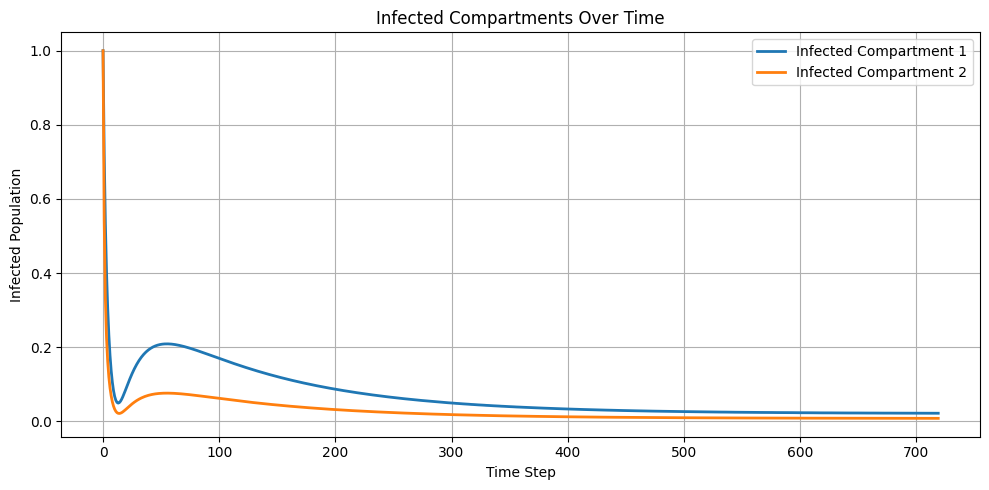

In [ ]:
import matplotlib.pyplot as plt

# Extract last two columns
infected_1 = df.iloc[:, -2]
infected_2 = df.iloc[:, -1]

# Create a time axis (e.g., assuming each row is a time step)
time = df.index

# Plot
plt.figure(figsize=(10, 5))
plt.plot(time, infected_1, label='Infected Compartment 1', linewidth=2)
plt.plot(time, infected_2, label='Infected Compartment 2', linewidth=2)
plt.xlabel('Time Step')
plt.ylabel('Infected Population')
plt.title('Infected Compartments Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

last_5_scalers = []              # scaling all of the coloumns

for col in df.columns:
    scaler = StandardScaler()
    df[col] = scaler.fit_transform(df[[col]])
    last_5_scalers.append(scaler)

last_5_scalers = last_5_scalers[-num_patches:]

In [ ]:
def get_data(df,lag=20):
    col_names = df.columns
    X = []
    y = []
    n = df.shape[0]
    for j in range(0,n-lag):
        tx = []
        ty = []
        for i in col_names[0:-num_patches]:
            values = df[i].values[j:j+lag+1]
            tx.append(values)
        for i in col_names[-num_patches:]:
            values = df[i].values[j:j+lag]
            tx.append(values)
        tx = np.concatenate(tx)
        X.append(tx)
        for i in col_names[-num_patches:]:
            ty.append(df[i].values[j+lag])
        y.append(ty)
    return np.array(X),np.array(y)

In [ ]:
lag = 3
X,y = get_data(df,lag)
print(X.shape)
print(y.shape)

(717, 26)
(717, 2)


In [ ]:
n = len(X)

training_ratio = int(0.5*len(X))

X_train,X_test = X[0:training_ratio],X[training_ratio:]
y_train,y_test = y[0:training_ratio],y[training_ratio:]

In [ ]:
class ELM:
    def __init__(self, input_dim, hidden_dim, output_dim, activation='sigmoid'):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.activation = activation
        self.W = np.random.randn(input_dim, hidden_dim)
        self.b = np.random.randn(hidden_dim)

    def _activation(self, x):
        if self.activation == 'sigmoid':
            x = np.clip(x, -500, 500)
            return 1 / (1 + np.exp(-x))
        elif self.activation == 'tanh':
            return np.tanh(x)
        elif self.activation == 'relu':
            return np.maximum(0, x)
        else:
            raise ValueError("Unsupported activation")

    def fit(self, X, y):
        # Import locally inside the method to bypass any global 'time' variable collision
        from time import perf_counter

        # Start tracking time and peak memory
        start_time = perf_counter()
        tracemalloc.start()

        # 1. Compute hidden layer activation matrix H
        H = self._activation(X @ self.W + self.b)

        # 2. Solve weights using direct pseudoinverse
        self.beta = np.linalg.pinv(H) @ y

        # Stop tracking
        end_time = perf_counter()
        current, peak_memory = tracemalloc.get_traced_memory()
        tracemalloc.stop()

        # Store training metrics for comparison
        self.training_metrics = {
            "training_time_sec": end_time - start_time,
            "peak_memory_mb": peak_memory / (1024 * 1024),
            "train_residual_norm": float(np.linalg.norm(H @ self.beta - y))
        }

    def predict(self, X):
        H = self._activation(X @ self.W + self.b)
        return H @ self.beta

# --- Execution Setup ---
n = int(1.02 * 1e6)           # hidden nodes
m = (lag + 1) * num_patches * num_patches + lag * num_patches + lag + 1

elm = ELM(input_dim=m, hidden_dim=n, output_dim=num_patches, activation='relu')

# Train the model
elm.fit(X_train, y_train)


# --- Print the Comparative Metrics ---
print("==========================================")
print("     STANDARD ELM TRAINING METRICS        ")
print("==========================================")
print(f"Training Time          : {elm.training_metrics['training_time_sec']:.4f} seconds")
print(f"Peak Memory Usage      : {elm.training_metrics['peak_memory_mb']:.2f} MB")
print(f"Training Residual Norm : {elm.training_metrics['train_residual_norm']:.4f}")
print("==========================================")

     STANDARD ELM TRAINING METRICS        
Training Time          : 266.6603 seconds
Peak Memory Usage      : 8359.81 MB
Training Residual Norm : 0.0000


In [ ]:
preds = []
for i in range(num_patches):
    preds.append([])

In [ ]:
print("length of test is",len(y_test))
t = []
t.append(X_test[0])
t = np.array(t)
pred = elm.predict(t)
print(pred)

length of test is 359
[[-0.42454567 -0.27468223]]


In [ ]:
for i in range(len(preds)):
    preds[i].append(pred[0][i])

for i in range(1,len(y_test)):
    print("Iteration number",i)
    t = []
    m = X_test[i]
    for i in range(num_patches):
        index = 10*(num_patches-i-1)+1
        m[-index]=pred[0][i]
    t.append(m)
    t = np.array(t)
    pred = elm.predict(t)
    for i in range(len(preds)):
        preds[i].append(pred[0][i])

Iteration number 1
Iteration number 2
Iteration number 3
Iteration number 4
Iteration number 5
Iteration number 6
Iteration number 7
Iteration number 8
Iteration number 9
Iteration number 10
Iteration number 11
Iteration number 12
Iteration number 13
Iteration number 14
Iteration number 15
Iteration number 16
Iteration number 17
Iteration number 18
Iteration number 19
Iteration number 20
Iteration number 21
Iteration number 22
Iteration number 23
Iteration number 24
Iteration number 25
Iteration number 26
Iteration number 27
Iteration number 28
Iteration number 29
Iteration number 30
Iteration number 31
Iteration number 32
Iteration number 33
Iteration number 34
Iteration number 35
Iteration number 36
Iteration number 37
Iteration number 38
Iteration number 39
Iteration number 40
Iteration number 41
Iteration number 42
Iteration number 43
Iteration number 44
Iteration number 45
Iteration number 46
Iteration number 47
Iteration number 48
Iteration number 49
Iteration number 50
Iteration

In [ ]:
actuals = []
for i in range(num_patches):
    actuals.append([])

for i in y_test:
    for j in range(len(actuals)):
        actuals[j].append(i[j])

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def plot_predictions(pred, act, scaler, i):
    # Ensure inputs are NumPy arrays
    pred = np.array(pred).reshape(-1, 1)
    act = np.array(act).reshape(-1, 1)

    # Inverse transform to original scale
    y_pred_original = scaler.inverse_transform(pred)
    y_test_original = scaler.inverse_transform(act)

    # Calculate R² and MSE
    r2 = r2_score(y_test_original, y_pred_original)
    mse = mean_squared_error(y_test_original, y_pred_original)

    # Create time axis in months (assuming 30 samples per month)
    months = np.arange(len(y_test_original)) / 30  # One tick per month

    # Plot

    plt.figure(figsize=(10, 5))
    plt.plot(months, y_test_original, label='Actual', linewidth=2)
    plt.plot(months, y_pred_original, label='Predicted', linewidth=2)
    plt.title(f'Actual vs Predicted of Cattle {i+1}\nR² = {r2:.4f} | MSE = {mse:.4e}', fontsize=14)
    plt.xlabel('Time (in months)')
    plt.ylabel(f'Cattle {i+1} infected compartment')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


    return r2, mse

     STANDARD ELM TRAINING METRICS        
Training Time          : 266.6603 seconds
Peak Memory Usage      : 8359.81 MB
Training Residual Norm : 0.0000
Length of predictions 359
Length of actual is 359


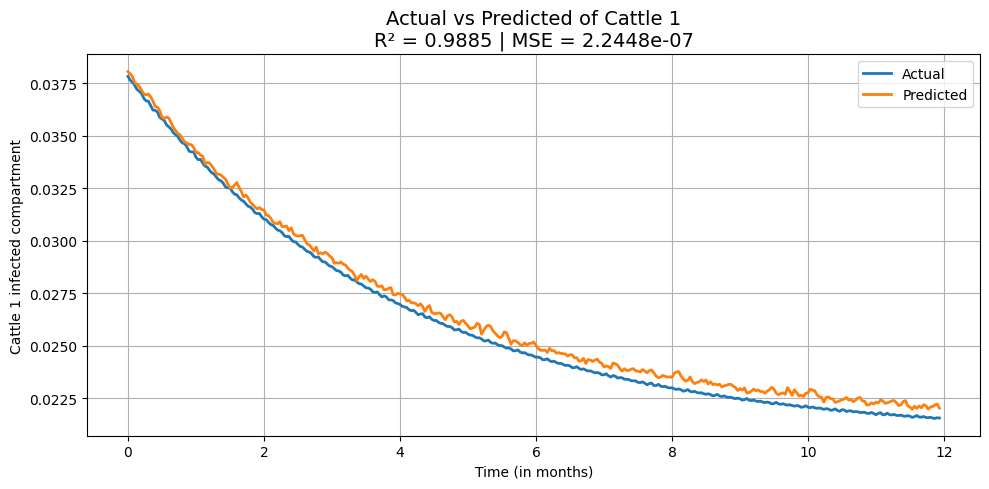

Cattle Population Number 1
R² Score : 0.9885
MSE      : 2.2448e-07
-----------------------------------
Length of predictions 359
Length of actual is 359


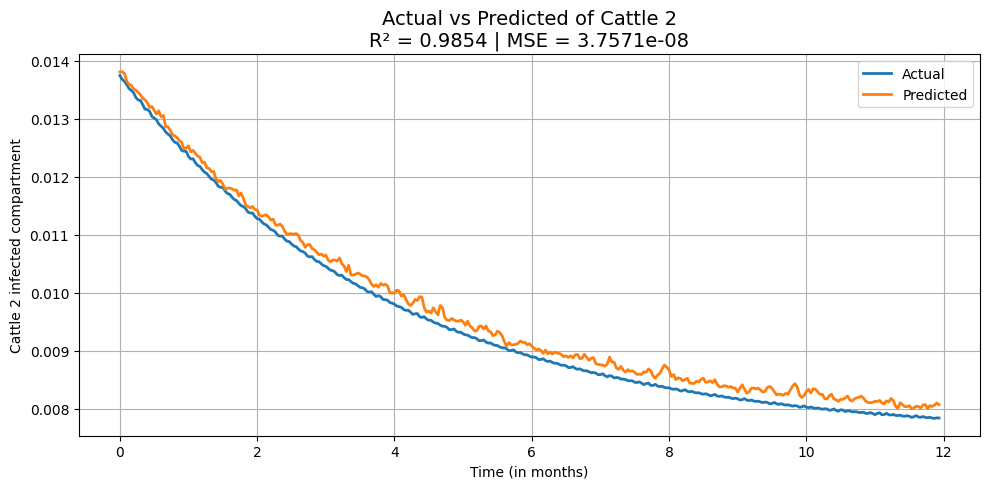

Cattle Population Number 2
R² Score : 0.9854
MSE      : 3.7571e-08
-----------------------------------


In [ ]:
print("==========================================")
print("     STANDARD ELM TRAINING METRICS        ")
print("==========================================")
print(f"Training Time          : {elm.training_metrics['training_time_sec']:.4f} seconds")
print(f"Peak Memory Usage      : {elm.training_metrics['peak_memory_mb']:.2f} MB")
print(f"Training Residual Norm : {elm.training_metrics['train_residual_norm']:.4f}")
print("==========================================")
for i in range(num_patches):
    print("Length of predictions",len(preds[i]))
    print("Length of actual is",len(actuals[i]))
    a,b = plot_predictions(preds[i], actuals[i],last_5_scalers[i],i)
    print(f"Cattle Population Number {i + 1}")
    print(f"R² Score : {a:.4f}")
    print(f"MSE      : {b:.4e}")
    print("-" * 35)

In [ ]:
'''

==========================================
     STANDARD ELM TRAINING METRICS
==========================================
Training Time          : 274.1094 seconds
Peak Memory Usage      : 8359.81 MB

==========================================
Cattle Population Number 1
R² Score : 0.9885
MSE      : 2.2448e-07
-----------------------------------
Cattle Population Number 2
R² Score : 0.9854
MSE      : 3.7571e-08
-----------------------------------


'''


'\n\n==========================================\n     STANDARD ELM TRAINING METRICS        \n==========================================\nTraining Time          : 274.1094 seconds\nPeak Memory Usage      : 8359.81 MB\nTraining Residual Norm : 0.0000\n==========================================\nLength of predictions 359\nLength of actual is 359\nCattle Population Number 1\nR² Score : 0.9885\nMSE      : 2.2448e-07\n-----------------------------------\nLength of predictions 359\nLength of actual is 359\nCattle Population Number 2\nR² Score : 0.9854\nMSE      : 3.7571e-08\n-----------------------------------\n\n\n'